# Práctica 2
Daniela Andrea Torres Gómez
## PARTE 1: SELECCIÓN DEL PROBLEMA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### Precio de venta de casas
Para realizar un problema de regresión

In [2]:
df = pd.read_csv('house_prices.csv')
df.head()

,Id,GrLivArea,YearBuilt,YearRemodAdd,1stFlrSF,2ndFlrSF,HasBasement,TotalBsmtSF,Garage,GarageArea,GarageCars,KitchenQual,TotRmsAbvGrd,BedroomAbvGr,TotalBathrooms,OverallQual,NumFloors,PoolQC,Pool,SalePrice
0,1,1710,2003,2003,856,854,Yes,856,Yes,548,2,Gd,8,3,3.5,7,2,No Pool,No,208500
1,2,1262,1976,1976,1262,0,Yes,1262,Yes,460,2,TA,6,3,2.5,6,1,No Pool,No,181500
2,3,1786,2001,2002,920,866,Yes,920,Yes,608,2,Gd,6,3,3.5,7,2,No Pool,No,223500
3,4,1717,1915,1970,961,756,Yes,756,Yes,642,3,Gd,7,3,2.0,7,2,No Pool,No,140000
4,5,2198,2000,2000,1145,1053,Yes,1145,Yes,836,3,Gd,9,4,3.5,8,2,No Pool,No,250000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              1460 non-null   int64  
 1   GrLivArea       1460 non-null   int64  
 2   YearBuilt       1460 non-null   int64  
 3   YearRemodAdd    1460 non-null   int64  
 4   1stFlrSF        1460 non-null   int64  
 5   2ndFlrSF        1460 non-null   int64  
 6   HasBasement     1460 non-null   str    
 7   TotalBsmtSF     1460 non-null   int64  
 8   Garage          1460 non-null   str    
 9   GarageArea      1460 non-null   int64  
 10  GarageCars      1460 non-null   int64  
 11  KitchenQual     1460 non-null   str    
 12  TotRmsAbvGrd    1460 non-null   int64  
 13  BedroomAbvGr    1460 non-null   int64  
 14  TotalBathrooms  1460 non-null   float64
 15  OverallQual     1460 non-null   int64  
 16  NumFloors       1460 non-null   int64  
 17  PoolQC          1460 non-null   str    
 18 

In [4]:
df.describe()

,Id,GrLivArea,YearBuilt,YearRemodAdd,1stFlrSF,2ndFlrSF,TotalBsmtSF,GarageArea,GarageCars,TotRmsAbvGrd,BedroomAbvGr,TotalBathrooms,OverallQual,NumFloors,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,1515.463699,1971.267808,1984.865753,1162.626712,346.992466,1057.429452,472.980137,1.767123,6.517808,2.866438,2.210616,6.099315,1.432192,180921.195890
std,421.610009,525.480383,30.202904,20.645407,386.587738,436.528436,438.705324,213.804841,0.747315,1.625393,0.815778,0.785399,1.382997,0.495550,79442.502883
min,1.000000,334.000000,1872.000000,1950.000000,334.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1.000000,1.000000,1.000000,34900.000000
25%,365.750000,1129.500000,1954.000000,1967.000000,882.000000,0.000000,795.750000,334.500000,1.000000,5.000000,2.000000,2.000000,5.000000,1.000000,129975.000000
50%,730.500000,1464.000000,1973.000000,1994.000000,1087.000000,0.000000,991.500000,480.000000,2.000000,6.000000,3.000000,2.000000,6.000000,1.000000,163000.000000
75%,1095.250000,1776.750000,2000.000000,2004.000000,1391.250000,728.000000,1298.250000,576.000000,2.000000,7.000000,3.000000,2.500000,7.000000,2.000000,214000.000000
max,1460.000000,5642.000000,2010.000000,2010.000000,4692.000000,2065.000000,6110.000000,1418.000000,4.000000,14.000000,8.000000,6.000000,10.000000,2.000000,755000.000000


## PARTE 2: MLP BASE – COMPARACION DE OPTIMIZADORES

Implemente una red neuronal multicapa para resolver el problema seleccionado. Establezca valores fijos para parámetros como numero de capas ocultas, numero de neuronas por capa, tasa de aprendizaje, funciones de activación. Compare el optimizador SGD con otros dos optimizadores más rápidos disponibles en Keras (momentum, nesterov, RMSProp, Adam). Seleccione como base el que mejor desempeño que logro en términos de tiempo y función de perdida para la siguiente etapa.

In [5]:
#Importacion de librerias
import numpy as np

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

In [6]:
import tensorflow as tf
from tensorflow import keras

In [7]:
# Organización de los conjuntos de entrenamiento, validación y prueba
# Es recomendable hacer un conjunto de Validación 
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']
X.head()

,Id,GrLivArea,YearBuilt,YearRemodAdd,1stFlrSF,2ndFlrSF,HasBasement,TotalBsmtSF,Garage,GarageArea,GarageCars,KitchenQual,TotRmsAbvGrd,BedroomAbvGr,TotalBathrooms,OverallQual,NumFloors,PoolQC,Pool
0,1,1710,2003,2003,856,854,Yes,856,Yes,548,2,Gd,8,3,3.5,7,2,No Pool,No
1,2,1262,1976,1976,1262,0,Yes,1262,Yes,460,2,TA,6,3,2.5,6,1,No Pool,No
2,3,1786,2001,2002,920,866,Yes,920,Yes,608,2,Gd,6,3,3.5,7,2,No Pool,No
3,4,1717,1915,1970,961,756,Yes,756,Yes,642,3,Gd,7,3,2.0,7,2,No Pool,No
4,5,2198,2000,2000,1145,1053,Yes,1145,Yes,836,3,Gd,9,4,3.5,8,2,No Pool,No


In [8]:
y.head()

0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

Revisar los atributos categoricos y mapearlos a categorias numéricas:

In [9]:
print( 'HasBasement', X['HasBasement'].unique())
print('Garage', X['Garage'].unique())
print('KitchenQual', X['KitchenQual'].unique())
print('PoolQC', X['PoolQC'].unique())
print('Pool', X['Pool'].unique())

HasBasement <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Garage <StringArray>
['Yes', 'No']
Length: 2, dtype: str
KitchenQual <StringArray>
['Gd', 'TA', 'Ex', 'Fa']
Length: 4, dtype: str
PoolQC <StringArray>
['No Pool', 'Ex', 'Fa', 'Gd']
Length: 4, dtype: str
Pool <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [10]:
HasBasement_mapping = {
		"Yes": 1, #Excellent
		"No": 0,  #Poor
}

#apply the mapping to convert HasBasement to numeric scale
X["HasBasement"] = X["HasBasement"].map(HasBasement_mapping)

In [11]:
Garage_mapping = {
		"Yes": 1, #has
		"No": 0,  #don't have
}

#apply the mapping to convert Garage to numeric scale
X["Garage"] = X["Garage"].map(Garage_mapping)

In [12]:
kitchen_quality_mapping = {
		"Ex": 5,  #Excellent
		"Gd": 4,  #Good
		"TA": 3,  #Typical/Average
		"Fa": 2,  #Fair
		"Po": 1   #Poor
}

#apply the mapping to convert KitchenQual to numeric scale
X["KitchenQual"] = X["KitchenQual"].map(kitchen_quality_mapping)

In [13]:
PoolQC_mapping = {
	"Ex": 5,  #Excellent
	"Gd": 4,  #Good
	"TA": 3,  #Average/Typical
	"Fa": 2,  #Fair
	"No Pool": 1  #No Pool
}

#apply the mapping to convert PoolQC to numeric scale
X["PoolQC"] = X["PoolQC"].map(PoolQC_mapping)

In [14]:
Pool_mapping = {
		"Yes": 1, #has
		"No": 0,  #don't have
}

#apply the mapping to convert Pool to numeric scale
X["Pool"] = X["Pool"].map(Pool_mapping)

In [15]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              1460 non-null   int64  
 1   GrLivArea       1460 non-null   int64  
 2   YearBuilt       1460 non-null   int64  
 3   YearRemodAdd    1460 non-null   int64  
 4   1stFlrSF        1460 non-null   int64  
 5   2ndFlrSF        1460 non-null   int64  
 6   HasBasement     1460 non-null   int64  
 7   TotalBsmtSF     1460 non-null   int64  
 8   Garage          1460 non-null   int64  
 9   GarageArea      1460 non-null   int64  
 10  GarageCars      1460 non-null   int64  
 11  KitchenQual     1460 non-null   int64  
 12  TotRmsAbvGrd    1460 non-null   int64  
 13  BedroomAbvGr    1460 non-null   int64  
 14  TotalBathrooms  1460 non-null   float64
 15  OverallQual     1460 non-null   int64  
 16  NumFloors       1460 non-null   int64  
 17  PoolQC          1460 non-null   int64  
 18 

In [16]:
X.head()

,Id,GrLivArea,YearBuilt,YearRemodAdd,1stFlrSF,2ndFlrSF,HasBasement,TotalBsmtSF,Garage,GarageArea,GarageCars,KitchenQual,TotRmsAbvGrd,BedroomAbvGr,TotalBathrooms,OverallQual,NumFloors,PoolQC,Pool
0,1,1710,2003,2003,856,854,1,856,1,548,2,4,8,3,3.5,7,2,1,0
1,2,1262,1976,1976,1262,0,1,1262,1,460,2,3,6,3,2.5,6,1,1,0
2,3,1786,2001,2002,920,866,1,920,1,608,2,4,6,3,3.5,7,2,1,0
3,4,1717,1915,1970,961,756,1,756,1,642,3,4,7,3,2.0,7,2,1,0
4,5,2198,2000,2000,1145,1053,1,1145,1,836,3,4,9,4,3.5,8,2,1,0


### Separar en entrenamiento, validación y prueba

In [17]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
x_train, x_valid, y_train, y_valid = train_test_split(x_train, y_train, test_size=0.1)

In [18]:
# Exploración de los datos
print("Datos de entrenamiento: ", x_train.shape)
print("Datos de prueba: ", x_test.shape)
print("Datos de validación: ", x_valid.shape)
print("Ejemplo de datos:", x_train.iloc[1,:])

Datos de entrenamiento:  (919, 19)
Datos de prueba:  (438, 19)
Datos de validación:  (103, 19)
Ejemplo de datos: Id                 102.0
GrLivArea         1732.0
YearBuilt         1985.0
YearRemodAdd      1985.0
1stFlrSF           977.0
2ndFlrSF           755.0
HasBasement          1.0
TotalBsmtSF        741.0
Garage               1.0
GarageArea         476.0
GarageCars           2.0
KitchenQual          4.0
TotRmsAbvGrd         7.0
BedroomAbvGr         3.0
TotalBathrooms       2.5
OverallQual          6.0
NumFloors            2.0
PoolQC               1.0
Pool                 0.0
Name: 101, dtype: float64


In [19]:
#Normalizacion de los datos
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_valid = scaler.transform(x_valid)
x_test = scaler.transform(x_test)

In [20]:
y_train.describe()

count       919.000000
mean     183822.988030
std       82994.742209
min       35311.000000
25%      131450.000000
50%      165400.000000
75%      219355.000000
max      755000.000000
Name: SalePrice, dtype: float64

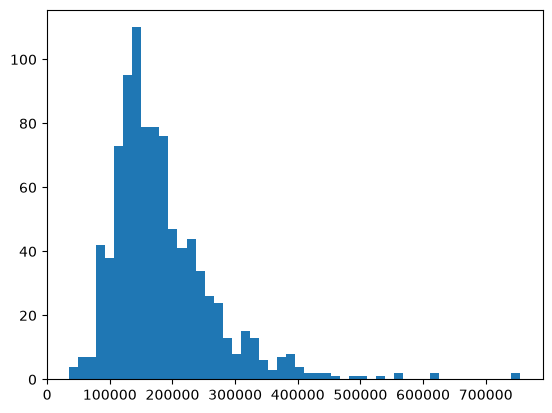

In [21]:
plt.hist(y_train, bins=50)
plt.show()

Reescalar los datos a través de un logaritmo:

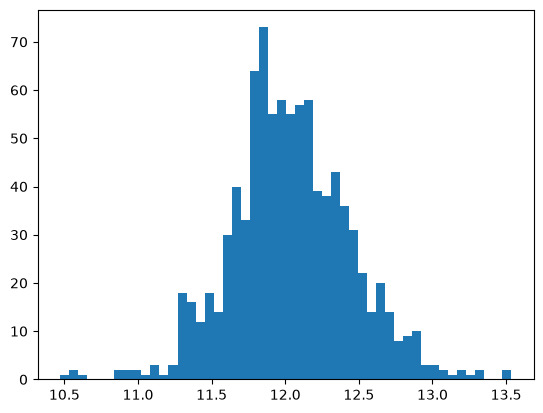

In [22]:
y_train_log = np.log1p(y_train)
plt.hist(y_train_log, bins=50)
plt.show()

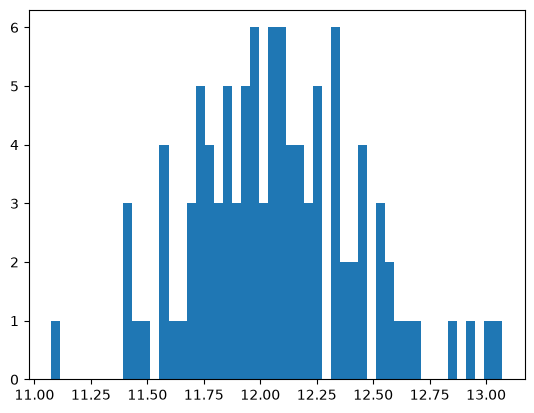

In [23]:
y_valid_log = np.log1p(y_valid)
plt.hist(y_valid_log, bins=50)
plt.show()

In [24]:
def unique_model(optimizer, loss):
    model = keras.Sequential([
        keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(1)
    ])
    
    model.compile(optimizer=optimizer, loss=loss, metrics=['mae'])
    model.summary()
    return model

In [44]:
def fitting_model(model, x_train, y_train, x_valid, y_valid, epochs=30):
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10
    )

    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        validation_data=(x_valid, y_valid),
        callbacks=[early_stop],
        verbose=2
    )
    
    #model.evaluate(x_test, y_test, verbose=0)

    history_df = pd.DataFrame(history.history)

    plt.figure(figsize=(8, 5))
    history_df[['loss', 'val_loss']].plot(ax=plt.gca())
    plt.grid(True)
    plt.ylim(bottom=0)
    plt.show()
    return history_df

In [54]:
def predict_and_evaluate(model, x_test, y_test ,log_target=True):
    y_pred = model.predict(x_test).flatten()
    print("Predicciones: ", y_pred[:5])

    if log_target:
        y_pred_eval = np.expm1(y_pred)
    else:
        y_pred_eval = y_pred
    
    print("Predicciones escala real: ", y_pred_eval[:5])
        
    mse = metrics.mean_squared_error(y_test, y_pred_eval)
    mae = metrics.mean_absolute_error(y_test, y_pred_eval)
    r2 = metrics.r2_score(y_test, y_pred_eval)
    
    print('Mean Squared Error (MSE):', mse)
    print('Mean Absolute Error (MAE):', mae)
    print('R-squared (R2):', r2)

    return y_pred_eval, mse, mae, r2

### Optimizador SGD

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 1s - 20ms/step - loss: 169.0607 - mae: 12.9853 - val_loss: 164.8305 - val_mae: 12.8230
Epoch 2/100
29/29 - 1s - 20ms/step - loss: 169.0607 - mae: 12.9853 - val_loss: 164.8305 - val_mae: 12.8230
Epoch 2/100
29/29 - 0s - 4ms/step - loss: 164.1280 - mae: 12.7950 - val_loss: 160.2876 - val_mae: 12.6460
Epoch 3/100
29/29 - 0s - 4ms/step - loss: 164.1280 - mae: 12.7950 - val_loss: 160.2876 - val_mae: 12.6460
Epoch 3/100
29/29 - 0s - 3ms/step - loss: 159.3995 - mae: 12.6096 - val_loss: 155.9266 - val_mae: 12.4733
Epoch 4/100
29/29 - 0s - 3ms/step - loss: 159.3995 - mae: 12.6096 - val_loss: 155.9266 - val_mae: 12.4733
Epoch 4/100
29/29 - 0s - 3ms/step - loss: 154.8403 - mae: 12.4280 - val_loss: 151.6916 - val_mae: 12.3032
Epoch 5/100
29/29 - 0s - 3ms/step - loss: 154.8403 - mae: 12.4280 - val_loss: 151.6916 - val_mae: 12.3032
Epoch 5/100
29/29 - 0s - 3ms/step - loss: 150.4077 - mae: 12.2486 - val_loss: 147.5496 - val_mae: 12.1342
Epoch 6/100
29/29 - 0s - 3ms/step - loss: 15

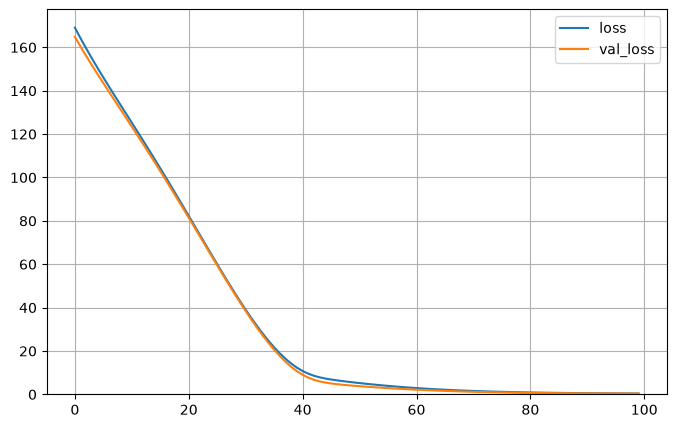

In [55]:
learning_rate = 0.001
model_sgd = unique_model(
    optimizer=keras.optimizers.SGD(learning_rate=learning_rate, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_sgd = fitting_model(model_sgd, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

In [56]:
y_pred_sgd, mse_sgd, mae_sgd, r2_sgd = predict_and_evaluate(model_sgd, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_sgd).describe()

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Predicciones:  [12.719933  11.64444   11.6219635 11.53886   11.775545 ]
Predicciones escala real:  [334345.3   114054.414 111519.48  102626.41  130032.2  ]
Mean Squared Error (MSE): 65827811328.0
Mean Absolute Error (MAE): 101824.3125
R-squared (R2): -11.542603492736816
Predicciones:  [12.719933  11.64444   11.6219635 11.53886   11.775545 ]
Predicciones escala real:  [334345.3   114054.414 111519.48  102626.41  130032.2  ]
Mean Squared Error (MSE): 65827811328.0
Mean Absolute Error (MAE): 101824.3125
R-squared (R2): -11.542603492736816


,0
count,4.380000e+02
mean,2.091731e+05
std,2.831975e+05
min,1.724568e+04
25%,9.646400e+04
50%,1.399523e+05
75%,2.240829e+05
max,2.736815e+06


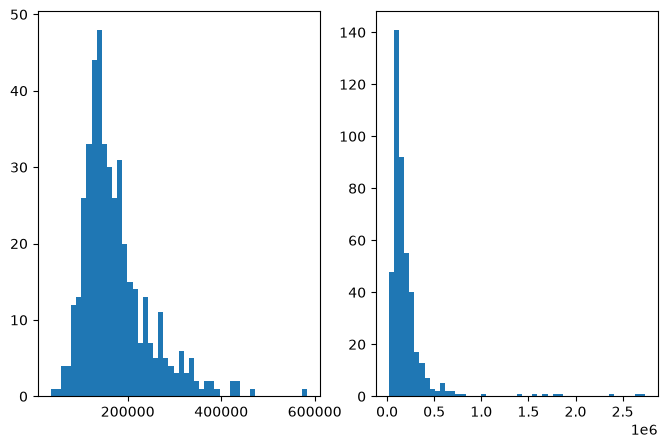

In [57]:
plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_sgd, bins=50)
plt.show()

### Optimizador ADAM

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 1s - 47ms/step - loss: 103.4010 - mae: 10.0733 - val_loss: 81.1067 - val_mae: 8.8780
Epoch 2/100
29/29 - 1s - 47ms/step - loss: 103.4010 - mae: 10.0733 - val_loss: 81.1067 - val_mae: 8.8780
Epoch 2/100
29/29 - 0s - 5ms/step - loss: 52.9714 - mae: 6.8329 - val_loss: 30.9202 - val_mae: 5.0722
Epoch 3/100
29/29 - 0s - 5ms/step - loss: 52.9714 - mae: 6.8329 - val_loss: 30.9202 - val_mae: 5.0722
Epoch 3/100
29/29 - 0s - 5ms/step - loss: 18.4326 - mae: 3.5851 - val_loss: 9.3946 - val_mae: 2.6298
Epoch 4/100
29/29 - 0s - 5ms/step - loss: 18.4326 - mae: 3.5851 - val_loss: 9.3946 - val_mae: 2.6298
Epoch 4/100
29/29 - 0s - 4ms/step - loss: 7.5719 - mae: 2.0846 - val_loss: 4.3813 - val_mae: 1.7816
Epoch 5/100
29/29 - 0s - 4ms/step - loss: 7.5719 - mae: 2.0846 - val_loss: 4.3813 - val_mae: 1.7816
Epoch 5/100
29/29 - 0s - 5ms/step - loss: 3.4771 - mae: 1.4317 - val_loss: 2.7770 - val_mae: 1.3938
Epoch 6/100
29/29 - 0s - 5ms/step - loss: 3.4771 - mae: 1.4317 - val_loss: 2.7770 - 

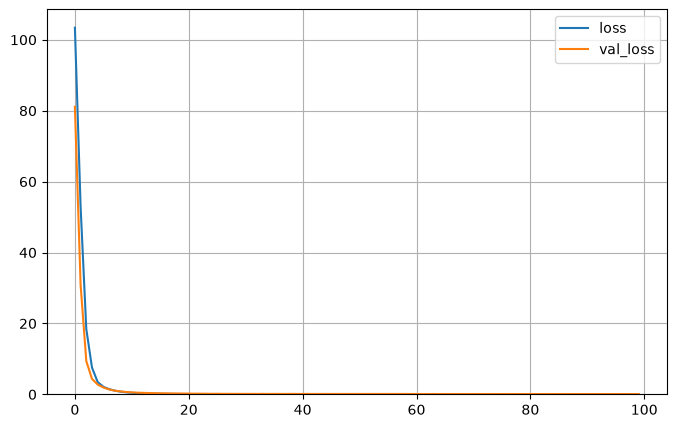

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Predicciones:  [11.446637 12.247152 11.960534 11.77568  11.723305]
Predicciones escala real:  [ 93585.1   208386.03  156455.62  130049.695 123413.61 ]
Mean Squared Error (MSE): 6315542016.0
Mean Absolute Error (MAE): 35318.83203125
R-squared (R2): -0.20334160327911377
Predicciones:  [11.446637 12.247152 11.960534 11.77568  11.723305]
Predicciones escala real:  [ 93585.1   208386.03  156455.62  130049.695 123413.61 ]
Mean Squared Error (MSE): 6315542016.0
Mean Absolute Error (MAE): 35318.83203125
R-squared (R2): -0.20334160327911377


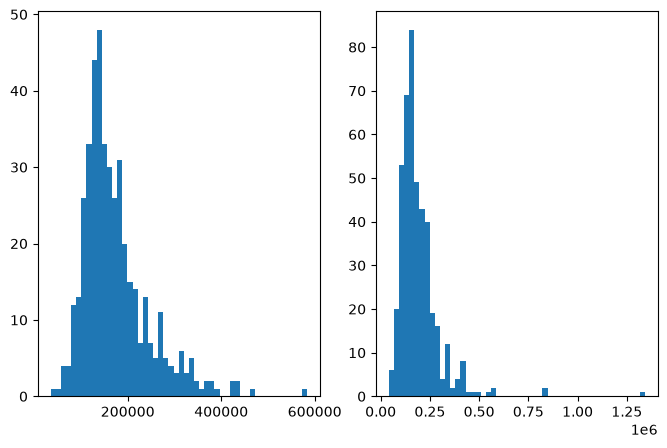

In [58]:
model_adam = unique_model(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_adam  = fitting_model(model_adam, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

y_pred_adam, mse_adam, mae_adam, r2_adam = predict_and_evaluate(model_adam, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_adam).describe()

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_adam, bins=50)
plt.show()

### Optimizador SGD con Momentum

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_33 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 1s - 26ms/step - loss: 137.0812 - mae: 11.6809 - val_loss: 121.6030 - val_mae: 11.0037
Epoch 2/100
29/29 - 1s - 26ms/step - loss: 137.0812 - mae: 11.6809 - val_loss: 121.6030 - val_mae: 11.0037
Epoch 2/100
29/29 - 0s - 5ms/step - loss: 102.7586 - mae: 10.0551 - val_loss: 83.2748 - val_mae: 9.0513
Epoch 3/100
29/29 - 0s - 5ms/step - loss: 102.7586 - mae: 10.0551 - val_loss: 83.2748 - val_mae: 9.0513
Epoch 3/100
29/29 - 0s - 4ms/step - loss: 61.9913 - mae: 7.6215 - val_loss: 41.9125 - val_mae: 6.2354
Epoch 4/100
29/29 - 0s - 4ms/step - loss: 61.9913 - mae: 7.6215 - val_loss: 41.9125 - val_mae: 6.2354
Epoch 4/100
29/29 - 0s - 4ms/step - loss: 25.6650 - mae: 4.5993 - val_loss: 11.2421 - val_mae: 2.9889
Epoch 5/100
29/29 - 0s - 4ms/step - loss: 25.6650 - mae: 4.5993 - val_loss: 11.2421 - val_mae: 2.9889
Epoch 5/100
29/29 - 0s - 5ms/step - loss: 7.9504 - mae: 2.2579 - val_loss: 3.9739 - val_mae: 1.6397
Epoch 6/100
29/29 - 0s - 5ms/step - loss: 7.9504 - mae: 2.2579 - val_l

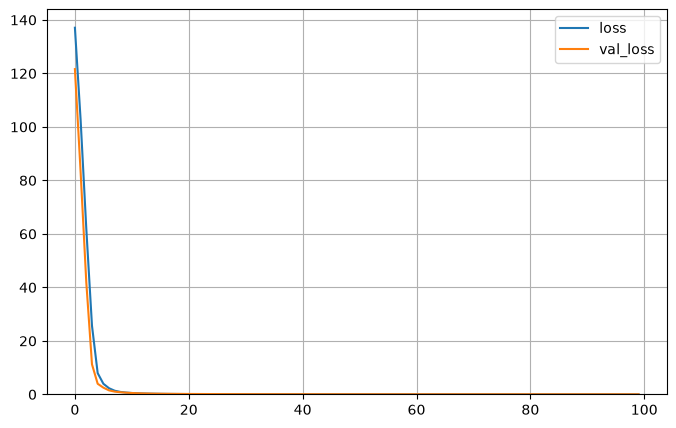

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Predicciones:  [11.846838 12.127739 11.791353 11.644649 12.181528]
Predicciones escala real:  [139641.1   184930.17  132104.11  114078.234 195149.84 ]
Mean Squared Error (MSE): 1470627072.0
Mean Absolute Error (MAE): 25655.580078125
R-squared (R2): 0.7197917699813843
Predicciones:  [11.846838 12.127739 11.791353 11.644649 12.181528]
Predicciones escala real:  [139641.1   184930.17  132104.11  114078.234 195149.84 ]
Mean Squared Error (MSE): 1470627072.0
Mean Absolute Error (MAE): 25655.580078125
R-squared (R2): 0.7197917699813843


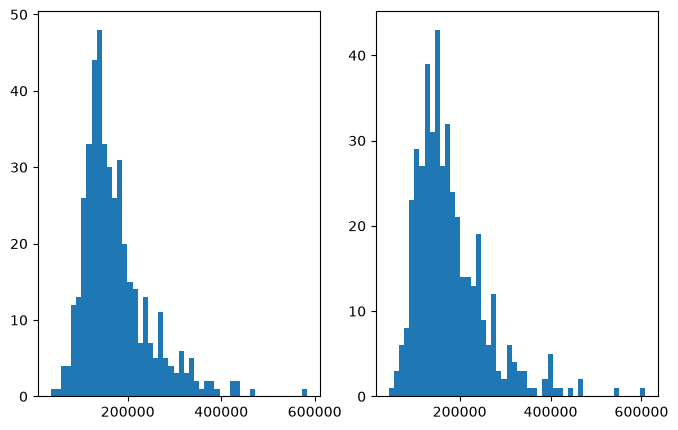

In [61]:
model_momentum = unique_model(
    optimizer=keras.optimizers.SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_momentum  = fitting_model(model_momentum, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

y_pred_momentum, mse_momentum, mae_momentum, r2_momentum = predict_and_evaluate(model_momentum, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_momentum).describe()

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_momentum, bins=50)
plt.show()

### Optimizador nesterov

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 1s - 29ms/step - loss: 126.9470 - mae: 11.2421 - val_loss: 109.8167 - val_mae: 10.4622
Epoch 2/100
29/29 - 1s - 29ms/step - loss: 126.9470 - mae: 11.2421 - val_loss: 109.8167 - val_mae: 10.4622
Epoch 2/100
29/29 - 0s - 3ms/step - loss: 88.9156 - mae: 9.3517 - val_loss: 69.0017 - val_mae: 8.2185
Epoch 3/100
29/29 - 0s - 3ms/step - loss: 88.9156 - mae: 9.3517 - val_loss: 69.0017 - val_mae: 8.2185
Epoch 3/100
29/29 - 0s - 5ms/step - loss: 47.0120 - mae: 6.5788 - val_loss: 29.7437 - val_mae: 5.0901
Epoch 4/100
29/29 - 0s - 5ms/step - loss: 47.0120 - mae: 6.5788 - val_loss: 29.7437 - val_mae: 5.0901
Epoch 4/100
29/29 - 0s - 5ms/step - loss: 16.6562 - mae: 3.5657 - val_loss: 9.1067 - val_mae: 2.5704
Epoch 5/100
29/29 - 0s - 5ms/step - loss: 16.6562 - mae: 3.5657 - val_loss: 9.1067 - val_mae: 2.5704
Epoch 5/100
29/29 - 0s - 5ms/step - loss: 7.3786 - mae: 2.1193 - val_loss: 4.8039 - val_mae: 1.8444
Epoch 6/100
29/29 - 0s - 5ms/step - loss: 7.3786 - mae: 2.1193 - val_loss: 4

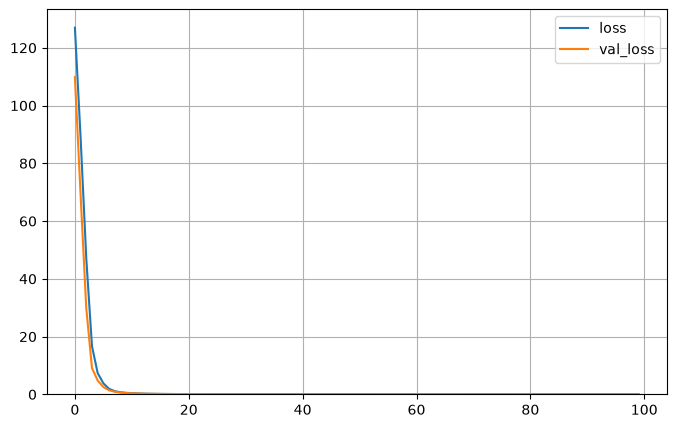

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Predicciones:  [11.565453  12.149044  11.891127  11.68964   11.9976425]
Predicciones escala real:  [105392.12 188912.4  145964.66 119328.05 162370.55]
Mean Squared Error (MSE): 4587394560.0
Mean Absolute Error (MAE): 29019.90234375
R-squared (R2): 0.1259337067604065
Predicciones:  [11.565453  12.149044  11.891127  11.68964   11.9976425]
Predicciones escala real:  [105392.12 188912.4  145964.66 119328.05 162370.55]
Mean Squared Error (MSE): 4587394560.0
Mean Absolute Error (MAE): 29019.90234375
R-squared (R2): 0.1259337067604065


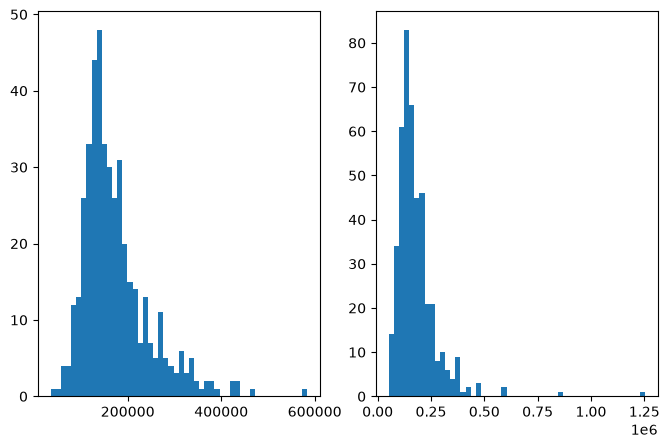

In [63]:
model_nesterov = unique_model(
    optimizer=keras.optimizers.SGD(learning_rate=0.001, momentum=0.9, nesterov=True, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_nesterov  = fitting_model(model_nesterov, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

y_pred_nesterov, mse_nesterov, mae_nesterov, r2_nesterov = predict_and_evaluate(model_nesterov, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_nesterov).describe()

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_nesterov, bins=50)
plt.show()

### Optimizador RMSProp

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 1s - 31ms/step - loss: 107.5715 - mae: 10.2778 - val_loss: 77.2529 - val_mae: 8.6964
Epoch 2/100
29/29 - 1s - 31ms/step - loss: 107.5715 - mae: 10.2778 - val_loss: 77.2529 - val_mae: 8.6964
Epoch 2/100
29/29 - 0s - 3ms/step - loss: 48.2274 - mae: 6.5964 - val_loss: 26.4321 - val_mae: 4.7066
Epoch 3/100
29/29 - 0s - 3ms/step - loss: 48.2274 - mae: 6.5964 - val_loss: 26.4321 - val_mae: 4.7066
Epoch 3/100
29/29 - 0s - 4ms/step - loss: 14.7546 - mae: 3.1758 - val_loss: 8.5054 - val_mae: 2.4884
Epoch 4/100
29/29 - 0s - 4ms/step - loss: 14.7546 - mae: 3.1758 - val_loss: 8.5054 - val_mae: 2.4884
Epoch 4/100
29/29 - 0s - 3ms/step - loss: 6.7202 - mae: 1.9636 - val_loss: 4.6401 - val_mae: 1.8077
Epoch 5/100
29/29 - 0s - 3ms/step - loss: 6.7202 - mae: 1.9636 - val_loss: 4.6401 - val_mae: 1.8077
Epoch 5/100
29/29 - 0s - 5ms/step - loss: 3.6611 - mae: 1.4551 - val_loss: 2.9167 - val_mae: 1.3833
Epoch 6/100
29/29 - 0s - 5ms/step - loss: 3.6611 - mae: 1.4551 - val_loss: 2.9167 - 

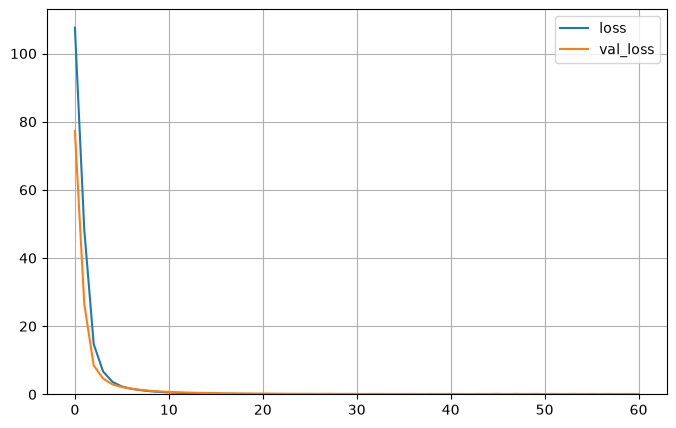

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Predicciones:  [11.208501 11.744044 11.656807 11.736708 11.596302]
Predicciones escala real:  [ 73753.766 125999.9   115473.73  125078.86  108694.1  ]
Mean Squared Error (MSE): 3092485120.0
Mean Absolute Error (MAE): 41999.70703125
R-squared (R2): 0.4107685685157776
Predicciones:  [11.208501 11.744044 11.656807 11.736708 11.596302]
Predicciones escala real:  [ 73753.766 125999.9   115473.73  125078.86  108694.1  ]
Mean Squared Error (MSE): 3092485120.0
Mean Absolute Error (MAE): 41999.70703125
R-squared (R2): 0.4107685685157776


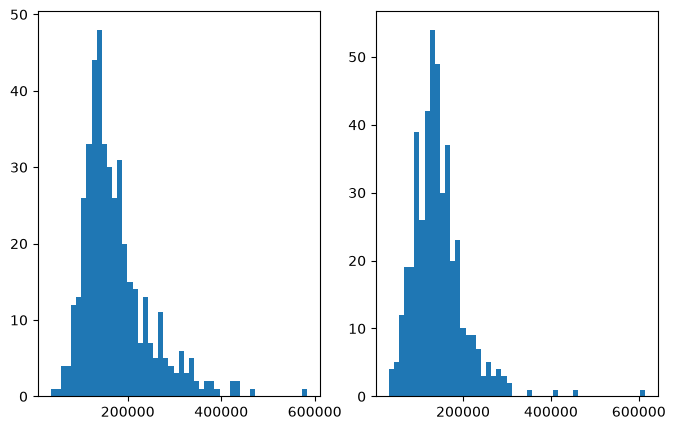

In [64]:
model_rmsprop = unique_model(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001, momentum=0.0, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_rmsprop  = fitting_model(model_rmsprop, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

y_pred_rmsprop, mse_rmsprop, mae_rmsprop, r2_rmsprop = predict_and_evaluate(model_rmsprop, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_rmsprop).describe()

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_rmsprop, bins=50)
plt.show()

El mejor fue SGD con momentum. Para Adam o SGD solo hay algunos valores tan grandes de predicción que dañan las métricas, como se ve en los histogramas anteriormente presentados:

In [66]:
# comparación de los resultados de los diferentes optimizadores
results = pd.DataFrame({
    'Optimizer': ['SGD with Nesterov', 'RMSprop', 'SGD', 'Adam', 'SGD with Momentum'],
    'MSE': [mse_nesterov, mse_rmsprop, mse_sgd, mse_adam, mse_momentum],
    'MAE': [mae_nesterov, mae_rmsprop, mae_sgd, mae_adam, mae_momentum],
    'R2': [r2_nesterov, r2_rmsprop, r2_sgd, r2_adam, r2_momentum]
})
results

,Optimizer,MSE,MAE,R2
0,SGD with Nesterov,4.587395e+09,29019.902344,0.125934
1,RMSprop,3.092485e+09,41999.707031,0.410769
2,SGD,6.582781e+10,101824.312500,-11.542603
3,Adam,6.315542e+09,35318.832031,-0.203342
4,SGD with Momentum,1.470627e+09,25655.580078,0.719792


# PARTE 2: MLP BASE – COMPARACION DE REGULARIZACIÓN

Empleando el optimizador y la arquitectura de la parte 2, determine si incluyendo una regularización (L1, L2, L1-L2) o barch-normalization se puede mejorar el resultado.

In [67]:
def regularizacion_l2(optimizer, loss, l2=0.01):
    
    #Modelo con regularizacion l2
    model = keras.models.Sequential([
        keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],), kernel_regularizer=keras.regularizers.l2(l2)),
        keras.layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(l2)),
        keras.layers.Dense(1)
    ])
    model.summary()

    #Compilacion
    model.compile(loss=loss,
                optimizer= optimizer,
                metrics=["mae"])
    
    return model

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_45 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 1s - 29ms/step - loss: 130.8593 - mae: 11.3811 - val_loss: 117.1483 - val_mae: 10.7748
Epoch 2/100
29/29 - 1s - 29ms/step - loss: 130.8593 - mae: 11.3811 - val_loss: 117.1483 - val_mae: 10.7748
Epoch 2/100
29/29 - 0s - 4ms/step - loss: 98.0323 - mae: 9.7915 - val_loss: 79.6297 - val_mae: 8.8375
Epoch 3/100
29/29 - 0s - 4ms/step - loss: 98.0323 - mae: 9.7915 - val_loss: 79.6297 - val_mae: 8.8375
Epoch 3/100
29/29 - 0s - 4ms/step - loss: 57.9971 - mae: 7.3432 - val_loss: 38.2772 - val_mae: 5.9631
Epoch 4/100
29/29 - 0s - 4ms/step - loss: 57.9971 - mae: 7.3432 - val_loss: 38.2772 - val_mae: 5.9631
Epoch 4/100
29/29 - 0s - 3ms/step - loss: 23.4593 - mae: 4.3107 - val_loss: 9.8397 - val_mae: 2.5927
Epoch 5/100
29/29 - 0s - 3ms/step - loss: 23.4593 - mae: 4.3107 - val_loss: 9.8397 - val_mae: 2.5927
Epoch 5/100
29/29 - 0s - 3ms/step - loss: 9.8228 - mae: 2.2942 - val_loss: 5.0276 - val_mae: 1.6910
Epoch 6/100
29/29 - 0s - 3ms/step - loss: 9.8228 - mae: 2.2942 - val_loss: 5

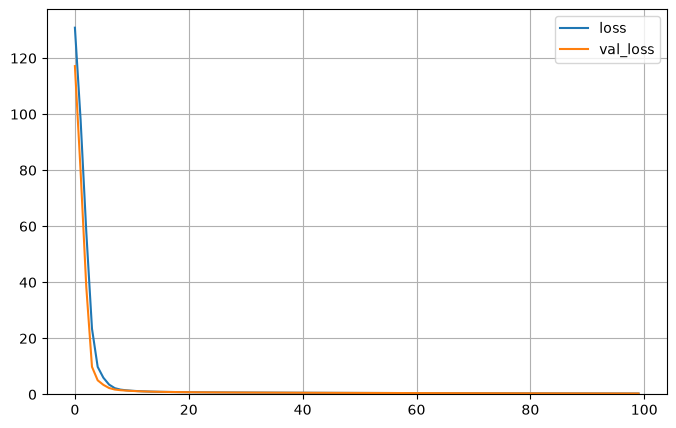

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Predicciones:  [11.600933  12.186732  11.7209425 11.751714  11.86119  ]
Predicciones escala real:  [109198.64  196168.1   123122.414 126969.97  141659.67 ]
Mean Squared Error (MSE): 1104152320.0
Mean Absolute Error (MAE): 20439.88671875
R-squared (R2): 0.7896186113357544
Predicciones:  [11.600933  12.186732  11.7209425 11.751714  11.86119  ]
Predicciones escala real:  [109198.64  196168.1   123122.414 126969.97  141659.67 ]
Mean Squared Error (MSE): 1104152320.0
Mean Absolute Error (MAE): 20439.88671875
R-squared (R2): 0.7896186113357544


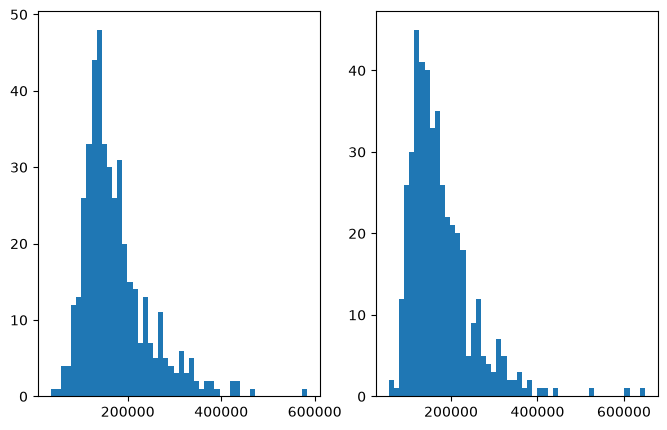

In [68]:
model_momentum_l2 = regularizacion_l2(
    optimizer=keras.optimizers.SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_momentum_l2  = fitting_model(model_momentum_l2, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

y_pred_momentum_l2, mse_momentum_l2, mae_momentum_l2, r2_momentum_l2 = predict_and_evaluate(model_momentum_l2, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_momentum_l2).describe()

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_momentum_l2, bins=50)
plt.show()

In [71]:
def regularizacion_l1(optimizer, loss, l1=0.01):
    
    #Modelo con regularizacion l1
    model = keras.models.Sequential([
        keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],), kernel_regularizer=keras.regularizers.l1(l1)),
        keras.layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l1(l1)),
        keras.layers.Dense(1)
    ])
    model.summary()
    #Compilacion
    model.compile(loss=loss,
                optimizer= optimizer,
                metrics=["mae"])
    return model

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_51 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 1s - 27ms/step - loss: 146.1333 - mae: 11.9012 - val_loss: 132.5011 - val_mae: 11.3167
Epoch 2/100
29/29 - 1s - 27ms/step - loss: 146.1333 - mae: 11.9012 - val_loss: 132.5011 - val_mae: 11.3167
Epoch 2/100
29/29 - 0s - 3ms/step - loss: 115.1058 - mae: 10.4777 - val_loss: 98.7684 - val_mae: 9.6713
Epoch 3/100
29/29 - 0s - 3ms/step - loss: 115.1058 - mae: 10.4777 - val_loss: 98.7684 - val_mae: 9.6713
Epoch 3/100
29/29 - 0s - 4ms/step - loss: 77.4452 - mae: 8.3744 - val_loss: 59.1938 - val_mae: 7.2849
Epoch 4/100
29/29 - 0s - 4ms/step - loss: 77.4452 - mae: 8.3744 - val_loss: 59.1938 - val_mae: 7.2849
Epoch 4/100
29/29 - 0s - 4ms/step - loss: 39.9924 - mae: 5.6129 - val_loss: 24.6959 - val_mae: 4.1729
Epoch 5/100
29/29 - 0s - 4ms/step - loss: 39.9924 - mae: 5.6129 - val_loss: 24.6959 - val_mae: 4.1729
Epoch 5/100
29/29 - 0s - 3ms/step - loss: 16.6240 - mae: 2.8847 - val_loss: 10.2454 - val_mae: 1.6708
Epoch 6/100
29/29 - 0s - 3ms/step - loss: 16.6240 - mae: 2.8847 - va

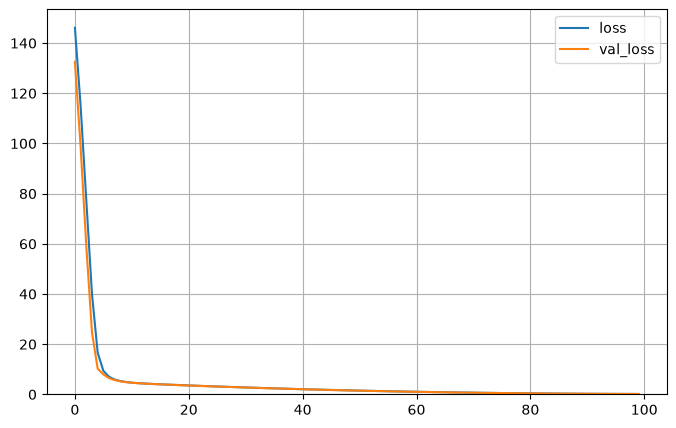

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Predicciones:  [11.783001 12.211877 11.870111 11.642117 11.888021]
Predicciones escala real:  [131005.336 201163.22  142929.17  113789.75  145512.11 ]
Mean Squared Error (MSE): 675679808.0
Mean Absolute Error (MAE): 18237.548828125
R-squared (R2): 0.8712583184242249
Predicciones:  [11.783001 12.211877 11.870111 11.642117 11.888021]
Predicciones escala real:  [131005.336 201163.22  142929.17  113789.75  145512.11 ]
Mean Squared Error (MSE): 675679808.0
Mean Absolute Error (MAE): 18237.548828125
R-squared (R2): 0.8712583184242249


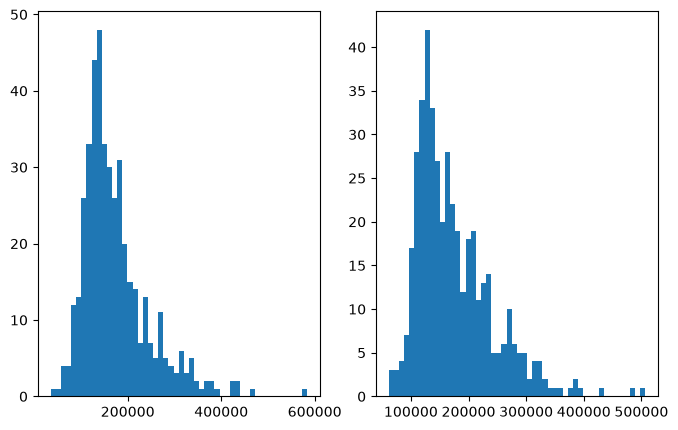

In [72]:
model_momentum_l1 = regularizacion_l1(
    optimizer=keras.optimizers.SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_momentum_l1  = fitting_model(model_momentum_l1, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

y_pred_momentum_l1, mse_momentum_l1, mae_momentum_l1, r2_momentum_l1 = predict_and_evaluate(model_momentum_l1, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_momentum_l1).describe()

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_momentum_l1, bins=50)
plt.show()

In [74]:
def regularizacion_l1_l2(optimizer, loss, l1=0.01, l2=0.01):
    
    #Modelo con regularizacion l2-l1
    model = keras.models.Sequential([
        keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],), kernel_regularizer=keras.regularizers.l1_l2(l1=l1, l2=l2)), #parámetro lambda = 0.01
        keras.layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l1_l2(l1=l1, l2=l2)),
        keras.layers.Dense(1)
    ])
    model.summary()
    #Compilacion
    model.compile(loss=loss,
                optimizer= optimizer,
                metrics=["mae"])
    return model

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_54 (Dense)                │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/29 - 2s - 56ms/step - loss: 126.8964 - mae: 11.0190 - val_loss: 112.0192 - val_mae: 10.3250
Epoch 2/100
29/29 - 2s - 56ms/step - loss: 126.8964 - mae: 11.0190 - val_loss: 112.0192 - val_mae: 10.3250
Epoch 2/100
29/29 - 0s - 9ms/step - loss: 91.0425 - mae: 9.2011 - val_loss: 71.3106 - val_mae: 8.0622
Epoch 3/100
29/29 - 0s - 9ms/step - loss: 91.0425 - mae: 9.2011 - val_loss: 71.3106 - val_mae: 8.0622
Epoch 3/100
29/29 - 0s - 8ms/step - loss: 49.2470 - mae: 6.4017 - val_loss: 31.3790 - val_mae: 4.8930
Epoch 4/100
29/29 - 0s - 8ms/step - loss: 49.2470 - mae: 6.4017 - val_loss: 31.3790 - val_mae: 4.8930
Epoch 4/100
29/29 - 0s - 9ms/step - loss: 18.5479 - mae: 3.2152 - val_loss: 11.5467 - val_mae: 2.1118
Epoch 5/100
29/29 - 0s - 9ms/step - loss: 18.5479 - mae: 3.2152 - val_loss: 11.5467 - val_mae: 2.1118
Epoch 5/100
29/29 - 0s - 7ms/step - loss: 10.7095 - mae: 1.8747 - val_loss: 9.1172 - val_mae: 1.6959
Epoch 6/100
29/29 - 0s - 7ms/step - loss: 10.7095 - mae: 1.8747 - val_los

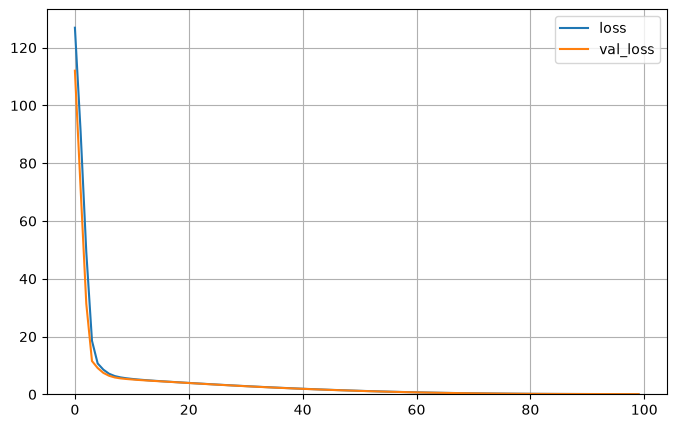

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Predicciones:  [11.807795 12.199347 11.946621 11.657183 11.858913]
Predicciones escala real:  [134294.06  198658.3   154293.89  115517.125 141337.56 ]
Mean Squared Error (MSE): 657243776.0
Mean Absolute Error (MAE): 17849.580078125
R-squared (R2): 0.8747710585594177
Predicciones:  [11.807795 12.199347 11.946621 11.657183 11.858913]
Predicciones escala real:  [134294.06  198658.3   154293.89  115517.125 141337.56 ]
Mean Squared Error (MSE): 657243776.0
Mean Absolute Error (MAE): 17849.580078125
R-squared (R2): 0.8747710585594177


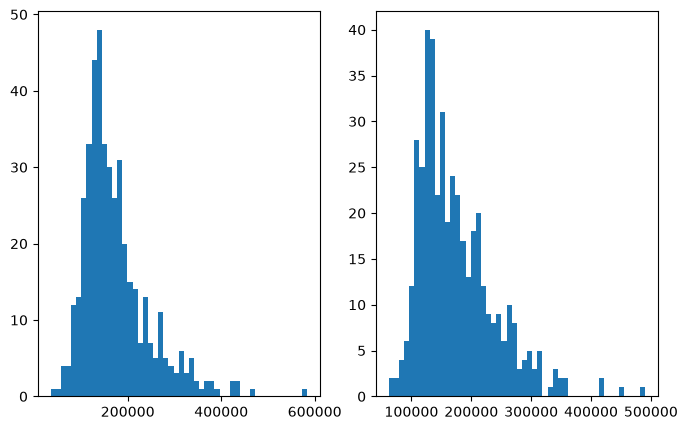

In [75]:
model_momentum_l1_l2 = regularizacion_l1_l2(
    optimizer=keras.optimizers.SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mean_squared_error'
 )

history_momentum_l1_l2  = fitting_model(model_momentum_l1_l2, x_train, y_train_log, x_valid, y_valid_log, epochs=100)

y_pred_momentum_l1_l2, mse_momentum_l1_l2, mae_momentum_l1_l2, r2_momentum_l1_l2 = predict_and_evaluate(model_momentum_l1_l2, x_test, y_test ,log_target=True)
pd.DataFrame(y_pred_momentum_l1_l2).describe()

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_momentum_l1_l2, bins=50)
plt.show()

Mejoró con la adición de la regularización L1 - L2

In [ ]:
# comparar las regularizaciones con el modelo original

results_2 = pd.DataFrame({
    'Optimizer': ['SGD with Momentum', 'SGD with momentum L1', 'SGD with momentum L2', 'SGD with momentum L1-L2',],
    'MSE': [mse_momentum, mse_momentum_l1, mse_momentum_l2, mse_momentum_l1_l2],
    'MAE': [mae_momentum, mae_momentum_l1, mae_momentum_l2, mae_momentum_l1_l2],
    'R2': [r2_momentum, r2_momentum_l1, r2_momentum_l2, r2_momentum_l1_l2]
})
results_2

,Optimizer,MSE,MAE,R2
0,SGD with Momentum,1.470627e+09,25655.580078,0.719792
1,SGD with momentum L1,6.756798e+08,18237.548828,0.871258
2,SGD with momentum L2,1.104152e+09,20439.886719,0.789619
3,SGD with momentum L1-L2,6.572438e+08,17849.580078,0.874771


# PARTE 3: OPTIMIZACION DE HIPERPARAMETROS

Realice la optimización de al menos dos hiperparámetros, partiendo del MLP Base logrado en la parte 2. Se sugiere, al menos, optimizar el número de neuronas en las capas ocultas y la tasa de aprendizaje. Si desea experimentar un poco más incluya el número de capas ocultas como parámetro a optimizar. Seleccione suficientes épocas (más de 30) y al menos 10 pruebas (num_trials) para este experimento. Una vez seleccionados los hiperparámetros, proceda a realizar la evaluación en términos de desempeño (Precisión o MSE de acuerdo con el problema).

In [ ]:
# Definición del modelo

from xml.parsers.expat import model


def build_model(hp):

    # Usamos el modelo Sequential
    model = keras.Sequential()
    neuronas_iniciales = x_train.shape[1:]

    # Vamos a elegir entre 32, 64 o 128 neuronas
    model.add(keras.layers.Dense(
        units=hp.Choice('units', values=[32, 64, 128]),
        activation=hp.Choice('activation', values=['relu', 'tanh']),
        input_shape=neuronas_iniciales,
        kernel_regularizer=keras.regularizers.l1_l2(l1=0.001, l2=0.001))
        )

    # Agregamos la capa de salida
    model.add(keras.layers.Dense(1))

    learning_rate = hp.Choice(
        'learning_rate',
        values=[1e-2, 1e-3, 1e-4]
        )

    model.compile(
        optimizer=keras.optimizers.SGD(
        learning_rate=learning_rate,
        momentum=0.9,
        clipnorm=1.0
        ),
    loss='mean_squared_error')

    return model

### RandomSearch

In [78]:
#Importar la libreria
import keras_tuner as kt

In [140]:
#Ahora vamos a aplica busqueda aleatoria, buscando minimazr la perdida
#de validacion
tuner_random_s = kt.RandomSearch(
    build_model, #Funcion que define el modelo
    objective='val_loss', #Objetivo a minimizar
    max_trials=10, #Numero de pruebas a realizar
    directory='Random_Search', #Carpeta para almenzar los experimentos
    project_name='regresion_sgd_momentum',
    overwrite=True
)

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
tuner_random_s.search(x_train, y_train_log, epochs=30, validation_data=(x_valid, y_valid_log))
best_model_random_s = tuner_random_s.get_best_models()[0]

Trial 10 Complete [00h 00m 19s]
val_loss: 0.03523220494389534

Best val_loss So Far: 0.03285032883286476
Total elapsed time: 00h 06m 12s


c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'sgd', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(store)


In [142]:
best_trial = tuner_random_s.oracle.get_best_trials(1)[0]
print(best_trial.score)

0.03285032883286476


In [143]:
best_model_random_s.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673 (2.63 KB)

 Trainable params: 673 (2.63 KB)

 Non-trainable params: 0 (0.00 B)

In [145]:
# extraer los hiperparámetros óptimos del mejor modelo
best_hps = tuner_random_s.get_best_hyperparameters(1)[0]
print(f"Mejor número de neuronas: {best_hps.get('units')},", 
      f"Mejor función de activación: {best_hps.get('activation')},",
      f"Mejor tasa de aprendizaje: {best_hps.get('learning_rate')},"
      )

Mejor número de neuronas: 32, Mejor función de activación: relu, Mejor tasa de aprendizaje: 0.01,


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
MAE:  334.1966033417305
MSE:  116268.76385500036
R2:   -793112.8888972676
MAE:  334.1966033417305
MSE:  116268.76385500036
R2:   -793112.8888972676


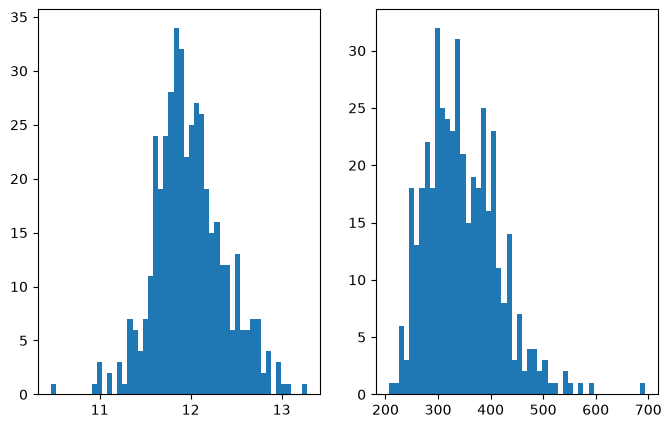

In [158]:
#Evaluacion del modelo
y_pred_random = best_model_random_s.predict(x_test)
y_test_log = np.log1p(y_test)

print("MAE: ", metrics.mean_absolute_error(y_test_log,y_pred_random))
print("MSE: ", metrics.mean_squared_error(y_test_log,y_pred_random))
print("R2:  ", metrics.r2_score(y_test_log,y_pred_random))

plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test_log, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_random, bins=50)
plt.show()

### Bayesiano

In [147]:
#Ahora vamos a aplica optimización bayesiana
tuner_bay = kt.BayesianOptimization(
    ####
    build_model, #Funcion que define el modelo
    objective='val_loss', #Objetivo a minimizar
    max_trials=10, #Numero de pruebas a realizar
    num_initial_points=3, # experimentos iniciales que se deben correr antes de que comience la optimización bayesiana
    directory='bayesian_tuner', #carpeta donde se almacenan los experimentos
    project_name='regresion_bay_sgd', 
    overwrite=True
)

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [148]:
tuner_bay.search(x_train, y_train_log, epochs=35, validation_data=(x_valid, y_valid_log))
best_model_bay = tuner_bay.get_best_models()[0]

Trial 10 Complete [00h 00m 09s]
val_loss: 0.043208375573158264

Best val_loss So Far: 0.034669600427150726
Total elapsed time: 00h 01m 30s


c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'sgd', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(store)


In [166]:
# extraer los hiperparámetros óptimos del mejor modelo
best_hps_bay = tuner_bay.get_best_hyperparameters(1)[0]
print(f"Mejor número de neuronas: {best_hps_bay.get('units')},", 
      f"Mejor función de activación: {best_hps_bay.get('activation')},",
      f"Mejor tasa de aprendizaje: {best_hps_bay.get('learning_rate')},"
      )

Mejor número de neuronas: 32, Mejor función de activación: relu, Mejor tasa de aprendizaje: 0.01,


In [162]:
best_trial = tuner_bay.oracle.get_best_trials(1)[0]
print(best_trial.score)

0.034669600427150726


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
MAE:  328.8752140519791
MSE:  112317.59219486052
R2:   -766160.4296367369


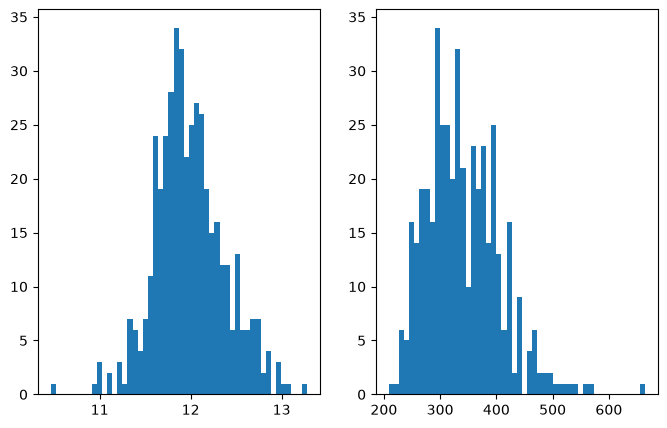

In [159]:
#Evaluacion del modelo
y_pred_bay = best_model_bay.predict(x_test)
y_test_log = np.log1p(y_test)

print("MAE: ", metrics.mean_absolute_error(y_test_log,y_pred_bay))
print("MSE: ", metrics.mean_squared_error(y_test_log,y_pred_bay))
print("R2:  ", metrics.r2_score(y_test_log,y_pred_bay))



plt.figure(figsize=(8, 5))
plt.subplot(1, 2, 1)
plt.hist(y_test_log, bins=50)
plt.subplot(1, 2, 2)
plt.hist(y_pred_bay, bins=50)
plt.show()